<a href="https://colab.research.google.com/github/ianpedrof-afk/TCC-IAN-PEDRO/blob/main/Que_d%C3%AA_tudo_certo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

caminho ='/content/drive/MyDrive/TCC IAN/PhiUSIIL_Phishing_URL_Dataset.csv'
df = pd.read_csv(caminho)

print(df.shape)   # (número de linhas, número de colunas)
df.head()         # mostra as 5 primeiras linhas

(235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [ ]:
print(df.columns.tolist())               # nomes de todas as colunas
print(df['label'].value_counts())        # quantas URLs em cada classe
print(df['URL'].duplicated().sum())      # quantas URLs repetidas
print(df.isnull().sum().sum())           # quantos valores ausentes

['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']
label
1    134850
0    100945
Name: count, dtype: int64
425
0


In [ ]:
!pip install tldextract -q

In [ ]:
feat_url = ['URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain',
            'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio',
            'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL',
            'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL',
            'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS',
            'CharContinuationRate']

feat_autores = ['URLSimilarityIndex', 'TLDLegitimateProb', 'URLCharProb']

descartar = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title', 'label']

feat_conteudo = [c for c in df.columns
                 if c not in feat_url + feat_autores + descartar]

print(len(feat_url), len(feat_autores), len(feat_conteudo))  # esperado: 19 3 28

19 3 28


In [ ]:
import tldextract

# 1. Remover URLs duplicadas (mantém a primeira ocorrência)
df = df.drop_duplicates(subset='URL').reset_index(drop=True)

# 2. Criar o alvo: phishing = 1, legítima = 0
df['phishing'] = 1 - df['label']

# 3. Extrair o domínio registrado (ex.: login.banco.com.br -> banco.com.br)
def dominio_registrado(url):
    ext = tldextract.extract(url)
    return f'{ext.domain}.{ext.suffix}' if ext.suffix else ext.domain

df['dominio_reg'] = df['URL'].apply(dominio_registrado)

# 4. Verificações
print('Tamanho após limpeza:', df.shape)
print(df['phishing'].value_counts())
print('Domínios únicos:', df['dominio_reg'].nunique())
dupla = df.groupby('dominio_reg')['phishing'].nunique()
print('Domínios com URLs das duas classes:', (dupla > 1).sum())

# 5. Investigar possíveis vieses
print(df.groupby('phishing')['URLSimilarityIndex'].describe())
print(df.groupby('phishing')['IsHTTPS'].mean())

# 6. Salvar no Drive
df.to_csv('/content/drive/MyDrive/TCC IAN/dataset_limpo.csv', index=False)

Tamanho após limpeza: (235370, 58)
phishing
0    134850
1    100520
Name: count, dtype: int64
Domínios únicos: 175509
Domínios com URLs das duas classes: 120
             count        mean        std         min         25%         50%  \
phishing                                                                        
0         134850.0  100.000000   0.000000  100.000000  100.000000  100.000000   
1         100520.0   49.651466  22.578566    0.155574   32.120613   51.478561   

                 75%    max  
phishing                     
0         100.000000  100.0  
1          67.307692  100.0  
phishing
0    1.000000
1    0.491226
Name: IsHTTPS, dtype: float64


In [ ]:
from urllib.parse import urlparse

# Regra de uma única característica
regra = (df['URLSimilarityIndex'] < 100).astype(int)
print('Acurácia da regra URLSimilarityIndex < 100:', (regra == df['phishing']).mean())
print('Phishing com índice 100 (escapariam):',
      ((df['URLSimilarityIndex'] == 100) & (df['phishing'] == 1)).sum())

# URLs com caminho além da página inicial, por classe
df['tem_caminho'] = df['URL'].apply(lambda u: urlparse(u).path not in ('', '/'))
print(df.groupby('phishing')['tem_caminho'].mean())

Acurácia da regra URLSimilarityIndex < 100: 0.9966605769639292
Phishing com índice 100 (escapariam): 786
phishing
0    0.000000
1    0.271429
Name: tem_caminho, dtype: float64


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_treino, idx_teste = next(gss.split(df, df['phishing'], groups=df['dominio_reg']))

treino = df.iloc[idx_treino].reset_index(drop=True)
teste = df.iloc[idx_teste].reset_index(drop=True)

print('Treino:', treino.shape, '| Teste:', teste.shape)
print('Proporção de phishing: treino', round(treino['phishing'].mean(), 3),
      '| teste', round(teste['phishing'].mean(), 3))
print('Domínios em comum (deve ser 0):',
      len(set(treino['dominio_reg']) & set(teste['dominio_reg'])))

treino.to_csv('/content/drive/MyDrive/TCC IAN/treino.csv', index=False)
teste.to_csv('/content/drive/MyDrive/TCC IAN/teste.csv', index=False)

Treino: (191335, 59) | Teste: (44035, 59)
Proporção de phishing: treino 0.436 | teste 0.388
Domínios em comum (deve ser 0): 0


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

cenarios = {
    'A (completo)': feat_url + feat_autores + feat_conteudo,
    'A sem URLSimilarityIndex': [c for c in feat_url + feat_autores + feat_conteudo
                                 if c != 'URLSimilarityIndex'],
    'B (somente URL)': feat_url,
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

for nome, colunas in cenarios.items():
    r = cross_validate(modelo, treino[colunas], treino['phishing'],
                       groups=treino['dominio_reg'], cv=cv,
                       scoring=['accuracy', 'precision', 'recall', 'f1'])
    print(f'\nCenário {nome}')
    for m in ['accuracy', 'precision', 'recall', 'f1']:
        print(f'  {m}: {r["test_" + m].mean():.4f} (± {r["test_" + m].std():.4f})')


Cenário A (completo)
  accuracy: 0.9998 (± 0.0001)
  precision: 1.0000 (± 0.0000)
  recall: 0.9996 (± 0.0001)
  f1: 0.9998 (± 0.0001)

Cenário A sem URLSimilarityIndex
  accuracy: 0.9991 (± 0.0004)
  precision: 0.9994 (± 0.0002)
  recall: 0.9984 (± 0.0010)
  f1: 0.9989 (± 0.0004)

Cenário B (somente URL)
  accuracy: 0.9959 (± 0.0004)
  precision: 0.9993 (± 0.0004)
  recall: 0.9910 (± 0.0021)
  f1: 0.9952 (± 0.0010)


In [ ]:
import re
import ipaddress
from urllib.parse import urlparse

def maior_sequencia(texto, teste):
    """Tamanho da maior sequência seguida de caracteres que passam no teste."""
    maior = atual = 0
    for c in texto:
        atual = atual + 1 if teste(c) else 0
        maior = max(maior, atual)
    return maior

def extrair_features(url):
    url = url.strip()
    n = max(len(url), 1)
    partes = urlparse(url)
    host = partes.hostname or ''
    ext = tldextract.extract(url)

    try:
        ipaddress.ip_address(host)
        dominio_ip = 1
    except ValueError:
        dominio_ip = 0

    letras = sum(c.isalpha() for c in url)
    digitos = sum(c.isdigit() for c in url)
    ofuscados = len(re.findall(r'%[0-9a-fA-F]{2}', url))   # ex.: %20, %2F
    outros = sum((not c.isalnum()) and c not in '=?&' for c in url)

    continuidade = (maior_sequencia(url, str.isalpha)
                    + maior_sequencia(url, str.isdigit)
                    + maior_sequencia(url, lambda c: not c.isalnum())) / n

    return {
        'URLLength': len(url),
        'DomainLength': len(host),
        'IsDomainIP': dominio_ip,
        'TLDLength': len(host.split('.')[-1]) if not dominio_ip else 0,
        'NoOfSubDomain': len(ext.subdomain.split('.')) if ext.subdomain else 0,
        'HasObfuscation': int(ofuscados > 0),
        'NoOfObfuscatedChar': ofuscados,
        'ObfuscationRatio': ofuscados / n,
        'NoOfLettersInURL': letras,
        'LetterRatioInURL': letras / n,
        'NoOfDegitsInURL': digitos,
        'DegitRatioInURL': digitos / n,
        'NoOfEqualsInURL': url.count('='),
        'NoOfQMarkInURL': url.count('?'),
        'NoOfAmpersandInURL': url.count('&'),
        'NoOfOtherSpecialCharsInURL': outros,
        'SpacialCharRatioInURL': outros / n,
        'IsHTTPS': int(partes.scheme == 'https'),
        'CharContinuationRate': continuidade,
    }

extrair_features('https://www.exemplo.com.br/login?id=123')   # teste rápido

{'URLLength': 39,
 'DomainLength': 18,
 'IsDomainIP': 0,
 'TLDLength': 2,
 'NoOfSubDomain': 1,
 'HasObfuscation': 0,
 'NoOfObfuscatedChar': 0,
 'ObfuscationRatio': 0.0,
 'NoOfLettersInURL': 27,
 'LetterRatioInURL': 0.6923076923076923,
 'NoOfDegitsInURL': 3,
 'DegitRatioInURL': 0.07692307692307693,
 'NoOfEqualsInURL': 1,
 'NoOfQMarkInURL': 1,
 'NoOfAmpersandInURL': 0,
 'NoOfOtherSpecialCharsInURL': 7,
 'SpacialCharRatioInURL': 0.1794871794871795,
 'IsHTTPS': 1,
 'CharContinuationRate': 0.3333333333333333}

In [ ]:
import numpy as np

X_treino_b = pd.DataFrame([extrair_features(u) for u in treino['URL']])
X_teste_b = pd.DataFrame([extrair_features(u) for u in teste['URL']])

comparacao = pd.DataFrame({
    'iguais (%)': [100 * np.isclose(X_treino_b[c], treino[c], atol=0.01).mean()
                   for c in feat_url],
    'correlacao': [X_treino_b[c].corr(treino[c]) for c in feat_url],
}, index=feat_url).round(3)
print(comparacao)

                            iguais (%)  correlacao
URLLength                       21.103       1.000
DomainLength                    99.982       1.000
IsDomainIP                      99.999       0.998
TLDLength                       99.722       0.969
NoOfSubDomain                   91.149       0.855
HasObfuscation                  99.816       0.716
NoOfObfuscatedChar              99.653       0.802
ObfuscationRatio                99.729       0.675
NoOfLettersInURL                 0.000       0.998
LetterRatioInURL                 0.067       0.507
NoOfDegitsInURL                 99.500       1.000
DegitRatioInURL                 99.350       1.000
NoOfEqualsInURL                 99.894       0.999
NoOfQMarkInURL                  99.996       0.999
NoOfAmpersandInURL              98.659       0.227
NoOfOtherSpecialCharsInURL       0.119       0.970
SpacialCharRatioInURL            0.636       0.264
IsHTTPS                         99.786       0.994
CharContinuationRate           

In [ ]:
r = cross_validate(modelo, X_treino_b, treino['phishing'],
                   groups=treino['dominio_reg'], cv=cv,
                   scoring=['accuracy', 'precision', 'recall', 'f1'])
print('Cenário B (extração própria)')
for m in ['accuracy', 'precision', 'recall', 'f1']:
    print(f'  {m}: {r["test_" + m].mean():.4f} (± {r["test_" + m].std():.4f})')

# Teste com URLs legítimas conhecidas
modelo.fit(X_treino_b, treino['phishing'])
urls_reais = [
    'https://www.google.com',
    'https://www.gov.br/pt-br/servicos',
    'https://pt.wikipedia.org/wiki/Phishing',
    'https://github.com/scikit-learn/scikit-learn',
    'https://docs.python.org/3/library/urllib.parse.html',
    'http://example.com',
]
X_reais = pd.DataFrame([extrair_features(u) for u in urls_reais])
for u, p in zip(urls_reais, modelo.predict_proba(X_reais)[:, 1]):
    print(f'{p:.2f}  {u}')

# Peso de cada característica na decisão
coef = pd.Series(modelo[-1].coef_[0], index=X_treino_b.columns)
print(coef.sort_values())

Cenário B (extração própria)
  accuracy: 0.9803 (± 0.0088)
  precision: 0.9914 (± 0.0015)
  recall: 0.9634 (± 0.0174)
  f1: 0.9771 (± 0.0091)
0.01  https://www.google.com
1.00  https://www.gov.br/pt-br/servicos
1.00  https://pt.wikipedia.org/wiki/Phishing
1.00  https://github.com/scikit-learn/scikit-learn
1.00  https://docs.python.org/3/library/urllib.parse.html
1.00  http://example.com
DomainLength                 -23.135070
IsHTTPS                      -15.810084
LetterRatioInURL              -1.217602
NoOfSubDomain                 -0.985764
NoOfAmpersandInURL            -0.800415
IsDomainIP                    -0.533746
SpacialCharRatioInURL         -0.388205
NoOfEqualsInURL               -0.272984
NoOfObfuscatedChar            -0.259336
HasObfuscation                -0.201425
ObfuscationRatio              -0.192934
CharContinuationRate           0.315517
TLDLength                      0.565870
DegitRatioInURL                1.180186
NoOfQMarkInURL                 2.941736
NoOfOtherS

In [ ]:
import math
from collections import Counter

PALAVRAS_SUSPEITAS = ['login', 'signin', 'secure', 'account', 'verify', 'update',
                      'bank', 'pay', 'wallet', 'confirm', 'support', 'auth']

def entropia(texto):
    """Mede o quanto os caracteres são variados (nomes aleatórios têm valor alto)."""
    if not texto:
        return 0.0
    n = len(texto)
    return -sum(q / n * math.log2(q / n) for q in Counter(texto).values())

def extrair_features_host(url):
    url = url.strip().lower()
    if '://' not in url:
        url = 'http://' + url
    host = urlparse(url).hostname or ''
    if host.startswith('www.'):
        host = host[4:]
    ext = tldextract.extract(host)

    try:
        ipaddress.ip_address(host)
        eh_ip = 1
    except ValueError:
        eh_ip = 0

    n = max(len(host), 1)
    nome = ext.domain
    letras_nome = [c for c in nome if c.isalpha()]
    digitos = sum(c.isdigit() for c in host)

    return {
        'tam_host': len(host),
        'tam_dominio': len(nome),
        'tam_tld': len(ext.suffix),
        'n_subdominios': len(ext.subdomain.split('.')) if ext.subdomain else 0,
        'n_digitos': digitos,
        'prop_digitos': digitos / n,
        'n_hifens': host.count('-'),
        'maior_seq_digitos': maior_sequencia(host, str.isdigit),
        'entropia_host': entropia(host),
        'prop_vogais': (sum(c in 'aeiou' for c in letras_nome) / len(letras_nome)
                        if letras_nome else 0),
        'eh_ip': eh_ip,
        'tem_punycode': int('xn--' in host),
        'tem_palavra_suspeita': int(any(p in host for p in PALAVRAS_SUSPEITAS)),
    }

extrair_features_host('https://www.secure-login.banco123.com.br/conta')

{'tam_host': 28,
 'tam_dominio': 8,
 'tam_tld': 6,
 'n_subdominios': 1,
 'n_digitos': 3,
 'prop_digitos': 0.10714285714285714,
 'n_hifens': 1,
 'maior_seq_digitos': 3,
 'entropia_host': 4.012188403968661,
 'prop_vogais': 0.4,
 'eh_ip': 0,
 'tem_punycode': 0,
 'tem_palavra_suspeita': 1}

In [ ]:
X_treino_h = pd.DataFrame([extrair_features_host(u) for u in treino['URL']])
X_teste_h = pd.DataFrame([extrair_features_host(u) for u in teste['URL']])

r = cross_validate(modelo, X_treino_h, treino['phishing'],
                   groups=treino['dominio_reg'], cv=cv,
                   scoring=['accuracy', 'precision', 'recall', 'f1'])
print('Cenário B2 (somente host)')
for m in ['accuracy', 'precision', 'recall', 'f1']:
    print(f'  {m}: {r["test_" + m].mean():.4f} (± {r["test_" + m].std():.4f})')

modelo.fit(X_treino_h, treino['phishing'])
X_reais = pd.DataFrame([extrair_features_host(u) for u in urls_reais])
for u, p in zip(urls_reais, modelo.predict_proba(X_reais)[:, 1]):
    print(f'{p:.2f}  {u}')

coef = pd.Series(modelo[-1].coef_[0], index=X_treino_h.columns)
print(coef.sort_values())

Cenário B2 (somente host)
  accuracy: 0.8023 (± 0.0203)
  precision: 0.8961 (± 0.0285)
  recall: 0.6014 (± 0.0834)
  f1: 0.7177 (± 0.0697)
0.22  https://www.google.com
0.20  https://www.gov.br/pt-br/servicos
0.56  https://pt.wikipedia.org/wiki/Phishing
0.23  https://github.com/scikit-learn/scikit-learn
0.77  https://docs.python.org/3/library/urllib.parse.html
0.22  http://example.com
maior_seq_digitos      -1.199105
tam_dominio            -1.092525
tam_tld                -0.435656
prop_vogais            -0.156751
entropia_host          -0.078804
prop_digitos            0.006894
tem_punycode            0.229129
tem_palavra_suspeita    0.250439
eh_ip                   0.476506
n_hifens                0.582560
n_subdominios           0.712575
tam_host                1.998910
n_digitos               3.488753
dtype: float64


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

modelos = {
    'Regressão Logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    'SVM (linear)': make_pipeline(StandardScaler(), LinearSVC(dual=False)),
}

dados = {
    'A': treino[feat_url + feat_autores + feat_conteudo],
    'B1': X_treino_b,
    'B2': X_treino_h,
}

metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
linhas = []

for cenario, X in dados.items():
    for nome, m in modelos.items():
        r = cross_validate(m, X, treino['phishing'], groups=treino['dominio_reg'],
                           cv=cv, scoring=metricas)
        linha = {'cenario': cenario, 'modelo': nome}
        linha.update({k: r['test_' + k].mean() for k in metricas})
        linha['recall_desvio'] = r['test_recall'].std()
        linhas.append(linha)
        print(cenario, '-', nome, 'concluído')

resultados = pd.DataFrame(linhas).round(4)
print(resultados.to_string(index=False))
resultados.to_csv('/content/drive/MyDrive/TCC IAN/resultados_cv.csv', index=False)

A - Regressão Logística concluído
A - Árvore de Decisão concluído
A - Random Forest concluído
A - SVM (linear) concluído
B1 - Regressão Logística concluído
B1 - Árvore de Decisão concluído
B1 - Random Forest concluído
B1 - SVM (linear) concluído
B2 - Regressão Logística concluído
B2 - Árvore de Decisão concluído
B2 - Random Forest concluído
B2 - SVM (linear) concluído
cenario              modelo  accuracy  precision  recall     f1  roc_auc  recall_desvio
      A Regressão Logística    0.9998     1.0000  0.9996 0.9998   1.0000         0.0001
      A   Árvore de Decisão    1.0000     1.0000  1.0000 1.0000   1.0000         0.0000
      A       Random Forest    1.0000     1.0000  1.0000 1.0000   1.0000         0.0000
      A        SVM (linear)    0.9999     1.0000  0.9998 0.9999   0.9999         0.0001
     B1 Regressão Logística    0.9803     0.9914  0.9634 0.9771   0.9940         0.0174
     B1   Árvore de Decisão    0.9873     0.9958  0.9756 0.9855   0.9791         0.0174
     B1      

In [ ]:
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(X_treino_h, treino['phishing'])

for u, p in zip(urls_reais, rf.predict_proba(X_reais)[:, 1]):
    print(f'{p:.2f}  {u}')

importancia = pd.Series(rf.feature_importances_, index=X_treino_h.columns)
print(importancia.sort_values(ascending=False).round(3))

0.25  https://www.google.com
0.18  https://www.gov.br/pt-br/servicos
0.94  https://pt.wikipedia.org/wiki/Phishing
0.21  https://github.com/scikit-learn/scikit-learn
0.78  https://docs.python.org/3/library/urllib.parse.html
0.21  http://example.com
n_subdominios           0.285
entropia_host           0.159
tam_host                0.100
prop_digitos            0.090
n_digitos               0.078
prop_vogais             0.070
maior_seq_digitos       0.068
tam_dominio             0.060
tam_tld                 0.045
n_hifens                0.036
tem_palavra_suspeita    0.010
eh_ip                   0.000
tem_punycode            0.000
dtype: float64


In [ ]:
from sklearn.model_selection import cross_val_predict

tem_sub = (X_treino_h['n_subdominios'] > 0).values
phish = (treino['phishing'] == 1).values

print('Proporção com subdomínio | legítimas:', round(tem_sub[~phish].mean(), 3),
      '| phishing:', round(tem_sub[phish].mean(), 3))

pred = cross_val_predict(rf, X_treino_h, treino['phishing'],
                         groups=treino['dominio_reg'], cv=cv)
for nome, grupo in [('com subdomínio', tem_sub), ('sem subdomínio', ~tem_sub)]:
    sel = phish & grupo
    print(f'Phishing {nome}: {sel.sum()} URLs, recall {pred[sel].mean():.3f}')

Proporção com subdomínio | legítimas: 0.029 | phishing: 0.556
Phishing com subdomínio: 46425 URLs, recall 0.941
Phishing sem subdomínio: 37008 URLs, recall 0.233


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder

X_treino_h2 = X_treino_h.assign(tld=[tldextract.extract(u).suffix for u in treino['URL']])
X_teste_h2 = X_teste_h.assign(tld=[tldextract.extract(u).suffix for u in teste['URL']])

def com_tld(m):
    codificador = ColumnTransformer(
        [('tld', TargetEncoder(random_state=42), ['tld'])], remainder='passthrough')
    return make_pipeline(codificador, m)

linhas = []
for nome, m in modelos.items():
    r = cross_validate(com_tld(m), X_treino_h2, treino['phishing'],
                       groups=treino['dominio_reg'], cv=cv, scoring=metricas)
    linha = {'modelo': nome}
    linha.update({k: r['test_' + k].mean() for k in metricas})
    linhas.append(linha)

print(pd.DataFrame(linhas).round(4).to_string(index=False))

             modelo  accuracy  precision  recall     f1  roc_auc
Regressão Logística    0.8513     0.9164  0.7145 0.8024   0.8909
  Árvore de Decisão    0.8192     0.8503  0.6936 0.7631   0.8071
      Random Forest    0.8360     0.8787  0.7093 0.7841   0.8715
       SVM (linear)    0.8510     0.9202  0.7102 0.8011   0.8903


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

def host_normalizado(url):
    url = url.strip().lower()
    if '://' not in url:
        url = 'http://' + url
    host = urlparse(url).hostname or ''
    return host[4:] if host.startswith('www.') else host

hosts_treino = treino['URL'].apply(host_normalizado)

modelo_ngrama = make_pipeline(
    TfidfVectorizer(analyzer='char', ngram_range=(2, 4), min_df=5, sublinear_tf=True),
    LogisticRegression(solver='liblinear'))

r = cross_validate(modelo_ngrama, hosts_treino, treino['phishing'],
                   groups=treino['dominio_reg'], cv=cv, scoring=metricas)
print('N-gramas de caracteres + Regressão Logística')
for m in metricas:
    print(f'  {m}: {r["test_" + m].mean():.4f} (± {r["test_" + m].std():.4f})')

N-gramas de caracteres + Regressão Logística
  accuracy: 0.8556 (± 0.0130)
  precision: 0.9303 (± 0.0169)
  recall: 0.7133 (± 0.0522)
  f1: 0.8068 (± 0.0398)
  roc_auc: 0.9141 (± 0.0164)


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

def montar(clf, escalar):
    return Pipeline([
        ('tld', ColumnTransformer([('tld', TargetEncoder(random_state=42), ['tld'])],
                                  remainder='passthrough')),
        ('escala', StandardScaler() if escalar else 'passthrough'),
        ('clf', clf),
    ])

buscas = {
    'Regressão Logística': (montar(LogisticRegression(max_iter=1000), True),
                            {'clf__C': [0.01, 0.1, 1, 10]}),
    'Árvore de Decisão': (montar(DecisionTreeClassifier(random_state=42), False),
                          {'clf__max_depth': [5, 10, 15, None],
                           'clf__min_samples_leaf': [1, 20, 100]}),
    'Random Forest': (montar(RandomForestClassifier(n_estimators=100, n_jobs=-1,
                                                    random_state=42), False),
                      {'clf__max_depth': [10, 20, None],
                       'clf__min_samples_leaf': [1, 20]}),
    'SVM (linear)': (montar(LinearSVC(dual=False), True),
                     {'clf__C': [0.01, 0.1, 1, 10]}),
}

melhores = {}
for nome, (pipe, grade) in buscas.items():
    busca = GridSearchCV(pipe, grade, scoring='roc_auc', cv=cv)
    busca.fit(X_treino_h2, treino['phishing'], groups=treino['dominio_reg'])
    melhores[nome] = busca.best_estimator_
    print(f'{nome}: AUC {busca.best_score_:.4f} com {busca.best_params_}')

Regressão Logística: AUC 0.8909 com {'clf__C': 10}
Árvore de Decisão: AUC 0.8940 com {'clf__max_depth': 15, 'clf__min_samples_leaf': 100}
Random Forest: AUC 0.9015 com {'clf__max_depth': 20, 'clf__min_samples_leaf': 20}
SVM (linear): AUC 0.8903 com {'clf__C': 0.1}


Regressão Logística: limiar 0.124 | precisão 0.531 | recall 0.964 | F2 0.829
Árvore de Decisão: limiar 0.145 | precisão 0.534 | recall 0.965 | F2 0.831
Random Forest: limiar 0.176 | precisão 0.545 | recall 0.961 | F2 0.834
SVM (linear): limiar -0.748 | precisão 0.528 | recall 0.967 | F2 0.829


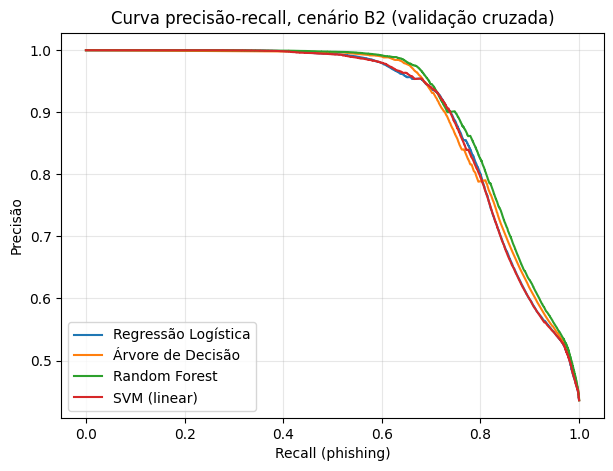

In [25]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

y = treino['phishing'].values
limiares = {}
plt.figure(figsize=(7, 5))

for nome, m in melhores.items():
    metodo = 'predict_proba' if hasattr(m, 'predict_proba') else 'decision_function'
    s = cross_val_predict(m, X_treino_h2, y, groups=treino['dominio_reg'],
                          cv=cv, method=metodo)
    s = s[:, 1] if s.ndim == 2 else s

    prec, rec, lim = precision_recall_curve(y, s)
    f2 = 5 * prec * rec / (4 * prec + rec + 1e-12)
    i = f2[:-1].argmax()
    limiares[nome] = lim[i]
    print(f'{nome}: limiar {lim[i]:.3f} | precisão {prec[i]:.3f} | '
          f'recall {rec[i]:.3f} | F2 {f2[i]:.3f}')
    plt.plot(rec, prec, label=nome)

plt.xlabel('Recall (phishing)')
plt.ylabel('Precisão')
plt.title('Curva precisão-recall, cenário B2 (validação cruzada)')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('/content/drive/MyDrive/TCC IAN/curva_pr_b2.png', dpi=150, bbox_inches='tight')
plt.show()

In [26]:
from sklearn.metrics import roc_curve

scores_cv = {}
linhas = []
n_pos, n_neg = (y == 1).sum(), (y == 0).sum()

for nome, m in melhores.items():
    metodo = 'predict_proba' if hasattr(m, 'predict_proba') else 'decision_function'
    s = cross_val_predict(m, X_treino_h2, y, groups=treino['dominio_reg'],
                          cv=cv, method=metodo)
    s = s[:, 1] if s.ndim == 2 else s
    scores_cv[nome] = s

    fpr, tpr, lim = roc_curve(y, s)
    for alvo in [0.01, 0.05, 0.10, 0.20]:
        i = np.searchsorted(fpr, alvo, side='right') - 1
        vp, fp = tpr[i] * n_pos, fpr[i] * n_neg
        linhas.append({'modelo': nome, 'FPR máximo': alvo, 'limiar': lim[i],
                       'recall': tpr[i], 'precisão': vp / (vp + fp + 1e-12)})

print(pd.DataFrame(linhas).round(3).to_string(index=False))

             modelo  FPR máximo  limiar  recall  precisão
Regressão Logística        0.01   0.844   0.601     0.979
Regressão Logística        0.05   0.486   0.725     0.918
Regressão Logística        0.10   0.339   0.765     0.855
Regressão Logística        0.20   0.240   0.816     0.759
  Árvore de Decisão        0.01   0.777   0.643     0.980
  Árvore de Decisão        0.05   0.445   0.714     0.917
  Árvore de Decisão        0.10   0.326   0.755     0.854
  Árvore de Decisão        0.20   0.222   0.822     0.766
      Random Forest        0.01   0.676   0.652     0.981
      Random Forest        0.05   0.421   0.721     0.918
      Random Forest        0.10   0.323   0.782     0.858
      Random Forest        0.20   0.231   0.830     0.762
       SVM (linear)        0.01   0.525   0.603     0.979
       SVM (linear)        0.05  -0.049   0.724     0.918
       SVM (linear)        0.10  -0.268   0.763     0.855
       SVM (linear)        0.20  -0.453   0.816     0.759


In [27]:
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

y_teste = teste['phishing'].values

def pontuar(m, X):
    return m.predict_proba(X)[:, 1] if hasattr(m, 'predict_proba') else m.decision_function(X)

def limiar_para_fpr(s, alvo):
    fpr, tpr, lim = roc_curve(y, s)
    return lim[np.searchsorted(fpr, alvo, side='right') - 1]

def avaliar(cenario, nome, s, limiar):
    pred = (s >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_teste, pred).ravel()
    return {'cenario': cenario, 'modelo': nome,
            'acuracia': accuracy_score(y_teste, pred),
            'precisao': precision_score(y_teste, pred),
            'recall': recall_score(y_teste, pred),
            'f1': f1_score(y_teste, pred),
            'auc': roc_auc_score(y_teste, s),
            'falsos_neg': fn, 'falsos_pos': fp}

colunas_a = feat_url + feat_autores + feat_conteudo
conjuntos = {'A': (treino[colunas_a], teste[colunas_a]),
             'B1': (X_treino_b, X_teste_b)}

linhas = []
for cenario, (X_tr, X_te) in conjuntos.items():
    for nome, m in modelos.items():
        m = clone(m).fit(X_tr, y)
        padrao = 0.5 if hasattr(m, 'predict_proba') else 0.0
        linhas.append(avaliar(cenario, nome, pontuar(m, X_te), padrao))

for nome, m in melhores.items():   # já treinados no treino completo pela busca
    lim = limiar_para_fpr(scores_cv[nome], 0.10)
    linhas.append(avaliar('B2', nome, pontuar(m, X_teste_h2), lim))

resultados_teste = pd.DataFrame(linhas).round(4)
print(resultados_teste.to_string(index=False))
resultados_teste.to_csv('/content/drive/MyDrive/TCC IAN/resultados_teste.csv', index=False)

cenario              modelo  acuracia  precisao  recall     f1    auc  falsos_neg  falsos_pos
      A Regressão Logística    0.9999    1.0000  0.9996 0.9998 1.0000           6           0
      A   Árvore de Decisão    1.0000    1.0000  1.0000 1.0000 1.0000           0           0
      A       Random Forest    1.0000    1.0000  1.0000 1.0000 1.0000           0           0
      A        SVM (linear)    0.9999    1.0000  0.9998 0.9999 1.0000           3           0
     B1 Regressão Logística    0.9882    0.9916  0.9780 0.9847 0.9954         376         142
     B1   Árvore de Decisão    0.9936    0.9953  0.9882 0.9917 0.9908         202          80
     B1       Random Forest    0.9948    0.9951  0.9916 0.9933 0.9972         144          83
     B1        SVM (linear)    0.9935    1.0000  0.9832 0.9915 0.9953         287           0
     B2 Regressão Logística    0.8290    0.8183  0.7189 0.7653 0.8722        4804        2728
     B2   Árvore de Decisão    0.8365    0.8313  0.7261 0.77

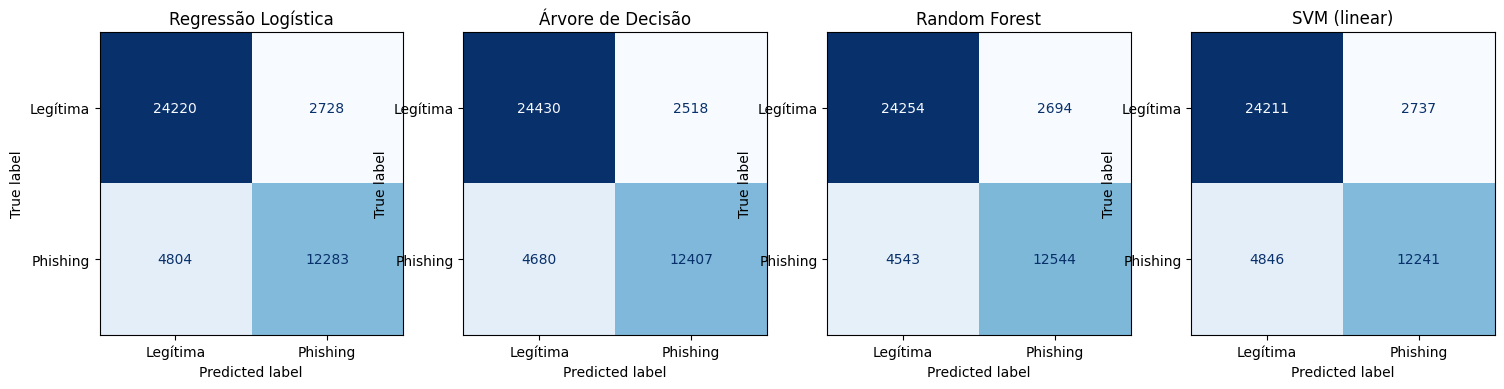

col_0                 legítima  phishing
row_0                                   
1. provável phishing       259     10287
2. suspeita               2435      2257
3. sem indícios          24254      4543
tld                     0.1223
n_subdominios           0.0620
tam_host                0.0095
n_hifens                0.0088
prop_vogais             0.0079
tam_dominio             0.0065
entropia_host           0.0047
n_digitos               0.0046
tam_tld                 0.0042
maior_seq_digitos       0.0041
prop_digitos            0.0028
tem_palavra_suspeita    0.0022
eh_ip                   0.0000
tem_punycode            0.0000
dtype: float64


['/content/drive/MyDrive/TCC IAN/modelo_b2.joblib']

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
import joblib

# Matrizes de confusão do cenário B2
fig, eixos = plt.subplots(1, 4, figsize=(18, 4))
for eixo, (nome, m) in zip(eixos, melhores.items()):
    lim = limiar_para_fpr(scores_cv[nome], 0.10)
    pred = (pontuar(m, X_teste_h2) >= lim).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_teste, pred, display_labels=['Legítima', 'Phishing'],
        cmap='Blues', colorbar=False, ax=eixo)
    eixo.set_title(nome)
plt.savefig('/content/drive/MyDrive/TCC IAN/matrizes_b2.png', dpi=150, bbox_inches='tight')
plt.show()

# Três faixas do protótipo (Random Forest)
rf_final = melhores['Random Forest']
lim_phishing = limiar_para_fpr(scores_cv['Random Forest'], 0.01)
lim_suspeita = limiar_para_fpr(scores_cv['Random Forest'], 0.10)
s_rf = pontuar(rf_final, X_teste_h2)
faixa = np.where(s_rf >= lim_phishing, '1. provável phishing',
                 np.where(s_rf >= lim_suspeita, '2. suspeita', '3. sem indícios'))
print(pd.crosstab(faixa, np.where(y_teste == 1, 'phishing', 'legítima')))

# Importância por permutação (queda de AUC ao embaralhar cada característica)
perm = permutation_importance(rf_final, X_teste_h2, y_teste, scoring='roc_auc',
                              n_repeats=5, random_state=42, n_jobs=-1)
print(pd.Series(perm.importances_mean, index=X_teste_h2.columns)
        .sort_values(ascending=False).round(4))

# Salvar o modelo do protótipo
joblib.dump({'modelo': rf_final, 'limiar_phishing': lim_phishing,
             'limiar_suspeita': lim_suspeita},
            '/content/drive/MyDrive/TCC IAN/modelo_b2.joblib')

In [ ]:
pasta = '/content/drive/MyDrive/TCC IAN/'

ext_phish = pd.read_csv(pasta + 'feed.txt', header=None, names=['URL'])['URL']
tranco = pd.read_csv(pasta + 'top-1m.csv', header=None, names=['posicao', 'dominio'])
ext_legit = 'https://' + tranco['dominio'].sample(5000, random_state=42)

dominios_treino = set(treino['dominio_reg'])

def preparar(urls):
    X = pd.DataFrame([extrair_features_host(u) for u in urls])
    X['tld'] = [tldextract.extract(u).suffix for u in urls]
    return X

for nome, urls in [('Phishing (OpenPhish)', ext_phish), ('Legítimas (Tranco)', ext_legit)]:
    urls = urls.dropna().drop_duplicates()
    hosts = urls.apply(host_normalizado)
    urls = urls[~hosts.duplicated()]                                  # um exemplo por host
    urls = urls[~urls.apply(dominio_registrado).isin(dominios_treino)]  # fora do treino
    s = pontuar(rf_final, preparar(urls))
    print(f'\n{nome}: {len(urls)} URLs')
    print(f'  provável phishing: {(s >= lim_phishing).mean():.3f}')
    print(f'  suspeita:          {((s >= lim_suspeita) & (s < lim_phishing)).mean():.3f}')
    print(f'  sem indícios:      {(s < lim_suspeita).mean():.3f}')